# Tier 1 Exploration: Real Image and COCO Mask

This notebook loads and visualizes the real test image and its COCO polygon annotations. It does not implement attribution or the directional matrix.

In [1]:
from pathlib import Path

import csv
import matplotlib.pyplot as plt
from PIL import Image

from src.data_utils import load_image_and_mask, load_mask_from_coco

c:\Users\Gabriel\Documents\Faculdade\Sis Int Hib\.venv_fixlip\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load the real image

The image is resized to 224 by 224 while the mask is loaded independently from the COCO JSON.

In [2]:
test_dir = Path("./tests")
image_path = test_dir / "test_img.JPEG"

with Image.open(image_path) as source_image:
    source_image_size = source_image.size

image_pil, _ = load_image_and_mask(
    image_path,
    mask_path=None,
    target_size=224,
)

mask_array, n_regions = load_mask_from_coco(
    test_dir / "test_mask.json",
    image_size=(224, 224),
    source_image_size=source_image_size,
)

print(f"Number of regions: {n_regions}")
print(f"Mask shape: {mask_array.shape}")

Number of regions: 5
Mask shape: (224, 224)


## Read the caption and visualize alignment

Caption: a baseball player throwing a ball


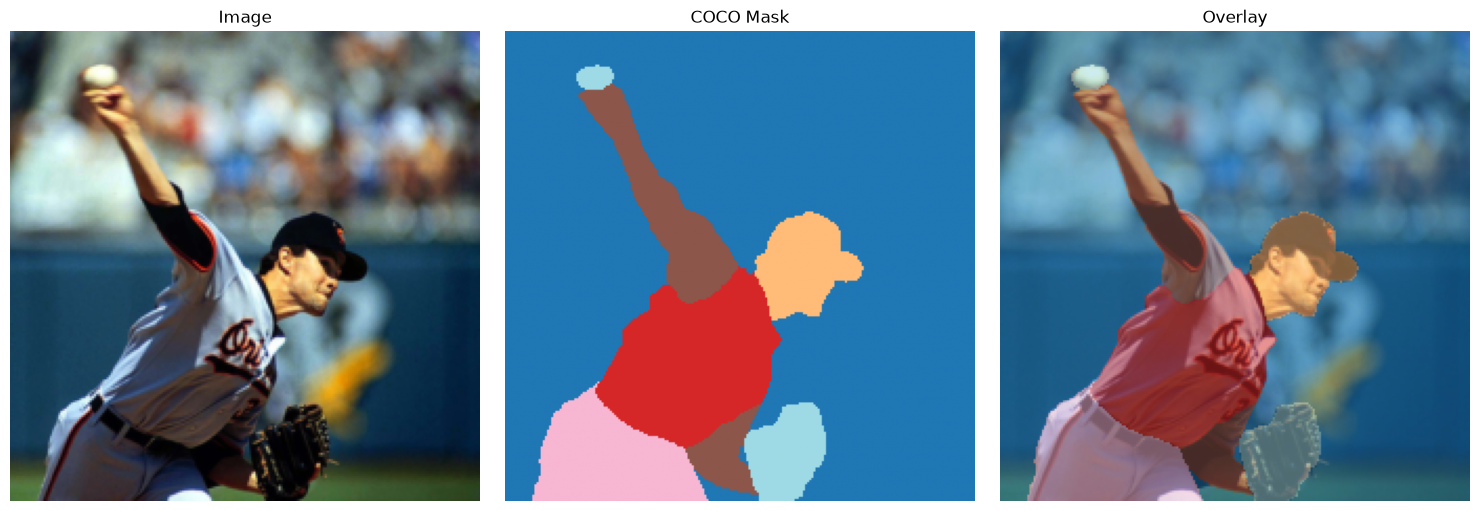

In [3]:
caption = None
with open(test_dir / "captions.csv", "r", newline="", encoding="utf-8") as csv_file:
    for row in csv.DictReader(csv_file):
        if row["image_file"] in {"test_img.jpeg", "test_img.jpg", "test_img.JPEG"}:
            caption = row["caption"]
            break

if caption is None:
    raise ValueError("Caption for test_img.jpeg was not found in captions.csv")

print(f"Caption: {caption}")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image_pil)
axes[0].set_title("Image")
axes[0].axis("off")

axes[1].imshow(mask_array, cmap="tab20")
axes[1].set_title("COCO Mask")
axes[1].axis("off")

axes[2].imshow(image_pil)
axes[2].imshow(mask_array, cmap="tab20", alpha=0.5)
axes[2].set_title("Overlay")
axes[2].axis("off")

fig.tight_layout()
plt.show()